In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the three data tables
filings = pd.read_parquet('filings.parquet')
news = pd.read_parquet('news.parquet')
prices = pd.read_parquet('prices.parquet')

# Quick overview
print("Filings shape:", filings.shape)
print("\nFirst 5 rows:")
print(filings.head())
print("\nData info:")
print(filings.info())
print("\nData statistics:")
print(filings.describe())

Filings shape: (73, 6)

First 5 rows:
   id symbol        date document_type  \
0   1   AAPL  2024-02-01          10-Q   
1   2   AAPL  2024-05-02          10-Q   
2   3   AAPL  2024-08-01          10-Q   
3   4   AAPL  2024-11-01          10-K   
4   5   AAPL  2025-01-31          10-Q   

                                         mda_content  \
0   Item 2. Management&#8217;s Discussion and Ana...   
1   Item 2. Management&#8217;s Discussion and Ana...   
2   Item 2. Management&#8217;s Discussion and Ana...   
3   Item 7. Management&#8217;s Discussion and Ana...   
4   Item 2. Management&#8217;s Discussion and Ana...   

                                        risk_content  
0   Item 1A. Risk Factors \n\nThe Company&#8217;s...  
1   Item 1A. Risk Factors \n\nThe Company&#8217;s...  
2   Item 1A. Risk Factors \n\nThe Company&#8217;s...  
3   Item 1A. Risk Factors \n\nThe Company&#8217;s...  
4   Item 1A. Risk Factors \n\nThe Company&#8217;s...  

Data info:
<class 'pandas.DataFrame'>
Ran

In [2]:
# Check missing values
print("Missing values:")
print(filings.isnull().sum())

# Missing value percentage
print("\nMissing value percentage:")
print((filings.isnull().sum() / len(filings) * 100).round(2), "%")

# Check duplicates
print("\nDuplicate rows:", filings.duplicated().sum())

# Check data types
print("\nData types:")
print(filings.dtypes)

Missing values:
id               0
symbol           0
date             0
document_type    0
mda_content      0
risk_content     0
dtype: int64

Missing value percentage:
id               0.0
symbol           0.0
date             0.0
document_type    0.0
mda_content      0.0
risk_content     0.0
dtype: float64 %

Duplicate rows: 0

Data types:
id                int32
symbol              str
date             object
document_type       str
mda_content         str
risk_content        str
dtype: object


In [3]:
# Check date range
print("Date range:", prices['date'].min(), "to", prices['date'].max())

# Check companies included
print("\nIncluded stocks:", prices['symbol'].unique())
print("Total companies:", prices['symbol'].nunique())

# Check record count per company
print("\nRecord count per company:")
print(prices['symbol'].value_counts().sort_index())

# Check trading volume and price
print("\nAdjusted close price statistics:")
print(prices.groupby('symbol')['adj_close'].describe())

print("\nTrading volume statistics:")
print(prices.groupby('symbol')['volume'].describe())

Date range: 2024-12-02 to 2026-03-31

Included stocks: <ArrowStringArray>
['AAPL', 'ADBE', 'AMZN', 'GOOGL', 'META', 'MSFT', 'NVDA', 'TSLA']
Length: 8, dtype: str
Total companies: 8

Record count per company:
symbol
AAPL     332
ADBE     332
AMZN     332
GOOGL    332
META     332
MSFT     332
NVDA     332
TSLA     332
Name: count, dtype: int64

Adjusted close price statistics:
        count        mean        std         min         25%         50%  \
symbol                                                                     
AAPL    332.0  237.853360  25.985487  171.671783  212.827354  240.636208   
ADBE    332.0  365.701717  61.710292  234.839996  335.837502  357.619995   
AMZN    332.0  218.538946  16.407313  167.320007  208.619999  221.864998   
GOOGL   332.0  227.879388  61.260751  144.199982  174.199821  199.080208   
META    332.0  658.872187  64.198096  483.152679  613.345398  654.409729   
MSFT    332.0  452.035387  49.911619  351.866241  405.748573  455.825485   
NVDA    332.0

In [4]:
# Check date range for news
print("News date range:", news['date'].min(), "to", news['date'].max())

# News count per company
print("\nNews records per company:")
print(news['symbol'].value_counts().sort_index())

# Check highlight text length
news['highlight_length'] = news['highlights'].str.len()
print("\nNews highlight length statistics:")
print(news['highlight_length'].describe())

# Look at sample news
print("\nSample news records:")
print(news[['symbol', 'date', 'highlights']].head(3))

News date range: 2024-12-01 to 2026-03-31

News records per company:
symbol
AAPL     486
ADBE     486
AMZN     486
GOOGL    486
META     486
MSFT     486
NVDA     486
TSLA     486
Name: count, dtype: int64

News highlight length statistics:
count     3888.000000
mean      4729.112912
std       1877.449853
min         25.000000
25%       3456.750000
50%       4719.500000
75%       5973.500000
max      12033.000000
Name: highlight_length, dtype: float64

Sample news records:
  symbol        date                                         highlights
0   AAPL  2024-12-01  Apple’s December 1, 2024 coverage centers on i...
1   AAPL  2024-12-02  The December 2, 2024 Apple coverage portrays a...
2   AAPL  2024-12-03  demonstrated strong financial performance, wit...


In [5]:
# Check filing types
print("Filing document types:")
print(filings['document_type'].value_counts())

# Filing count per company
print("\nFilings per company:")
print(filings['symbol'].value_counts().sort_index())

# Check MDA content length
print("\nMDA content length statistics:")
print(filings['mda_content'].str.len().describe())

print("\nRisk content length statistics:")
print(filings['risk_content'].str.len().describe())

Filing document types:
document_type
10-Q    51
10-K    22
Name: count, dtype: int64

Filings per company:
symbol
AAPL      9
ADBE     10
AMZN      9
GOOGL     9
META      9
MSFT      9
NVDA      9
TSLA      9
Name: count, dtype: int64

MDA content length statistics:
count       73.000000
mean     44449.863014
std      14079.207455
min      15930.000000
25%      35978.000000
50%      46697.000000
75%      51962.000000
max      76907.000000
Name: mda_content, dtype: float64

Risk content length statistics:
count        73.000000
mean      66262.027397
std       56218.879129
min         333.000000
25%       12557.000000
50%       66162.000000
75%       75317.000000
max      196794.000000
Name: risk_content, dtype: float64


In [6]:
# Check if symbols are consistent across tables
print("Companies in Prices:", sorted(prices['symbol'].unique()))
print("Companies in News:", sorted(news['symbol'].unique()))
print("Companies in Filings:", sorted(filings['symbol'].unique()))

# Merge prices and news by symbol and date
merged_data = prices.merge(news, on=['symbol', 'date'], how='left')
print("\nMerged prices + news shape:", merged_data.shape)
print("News records matched:", merged_data['highlights'].notna().sum(), "/", len(merged_data))

# Merge filings (note: filings data is sparse)
full_data = prices.merge(filings, on=['symbol', 'date'], how='left')
print("\nFull data (prices + filings) shape:", full_data.shape)
print("Records with filing data:", full_data['document_type'].notna().sum())

Companies in Prices: ['AAPL', 'ADBE', 'AMZN', 'GOOGL', 'META', 'MSFT', 'NVDA', 'TSLA']
Companies in News: ['AAPL', 'ADBE', 'AMZN', 'GOOGL', 'META', 'MSFT', 'NVDA', 'TSLA']
Companies in Filings: ['AAPL', 'ADBE', 'AMZN', 'GOOGL', 'META', 'MSFT', 'NVDA', 'TSLA']

Merged prices + news shape: (2656, 12)
News records matched: 2656 / 2656

Full data (prices + filings) shape: (2656, 13)
Records with filing data: 41


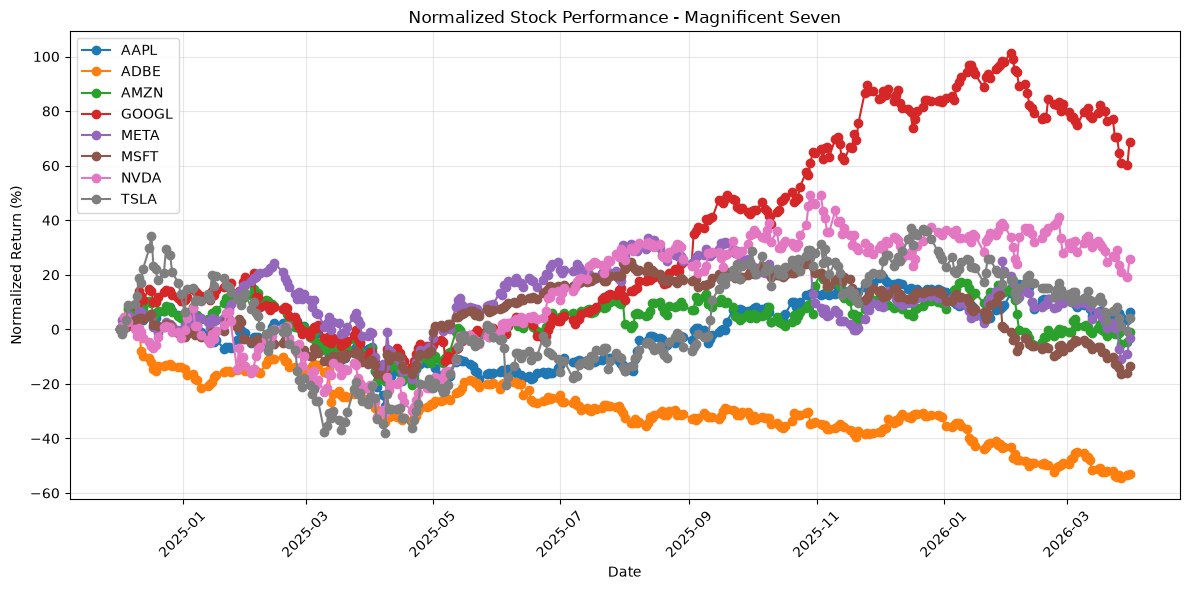

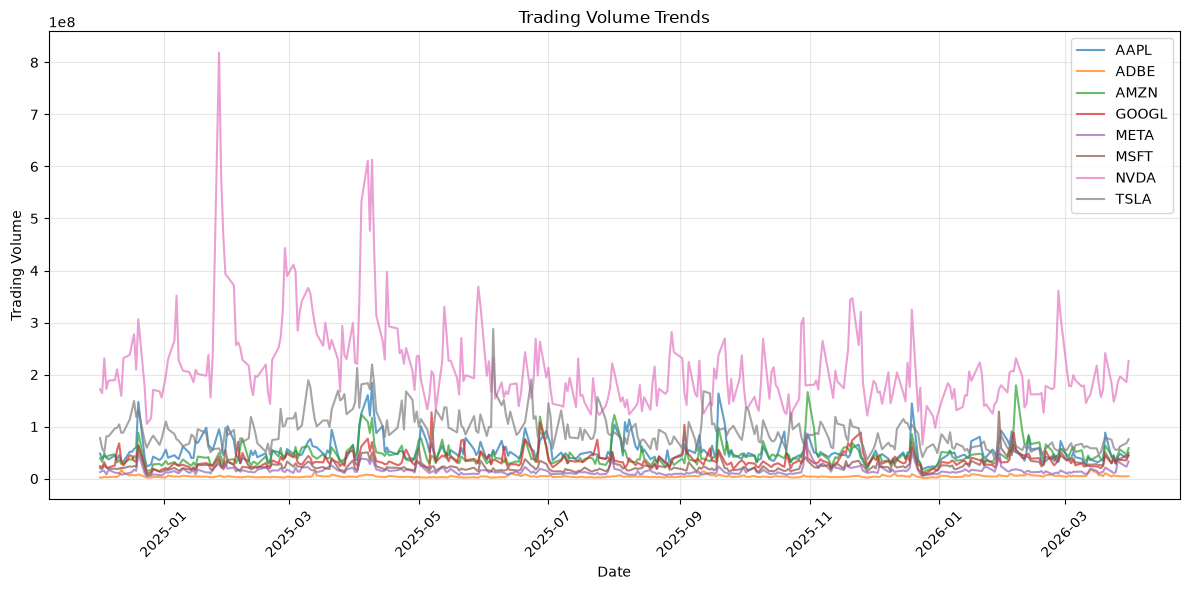

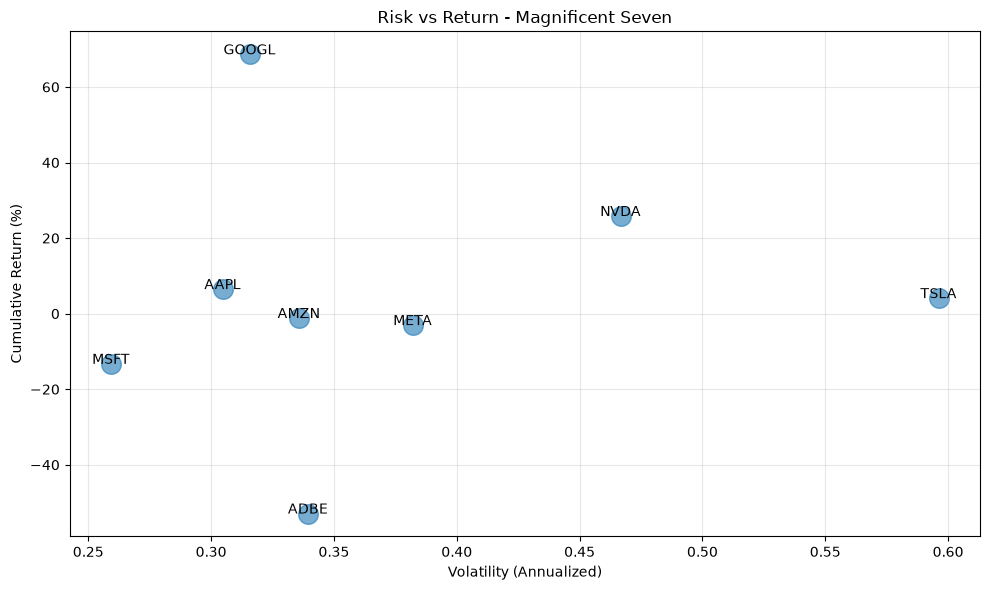

In [7]:
# Calculate normalized stock performance
prices['normalized_price'] = prices.groupby('symbol')['adj_close'].transform(
    lambda x: (x / x.iloc[0] - 1) * 100  # Percentage change from first day
)

# Plot normalized stock performance
plt.figure(figsize=(12, 6))
for symbol in prices['symbol'].unique():
    data = prices[prices['symbol'] == symbol].sort_values('date')
    plt.plot(data['date'], data['normalized_price'], label=symbol, marker='o')

plt.xlabel('Date')
plt.ylabel('Normalized Return (%)')
plt.title('Normalized Stock Performance - Magnificent Seven')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Trading volume trends
plt.figure(figsize=(12, 6))
for symbol in prices['symbol'].unique():
    data = prices[prices['symbol'] == symbol].sort_values('date')
    plt.plot(data['date'], data['volume'], label=symbol, alpha=0.7)

plt.xlabel('Date')
plt.ylabel('Trading Volume')
plt.title('Trading Volume Trends')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Risk vs Return (calculate volatility and cumulative return)
price_stats = prices.groupby('symbol').apply(lambda x: pd.Series({
    'cumulative_return': ((x['adj_close'].iloc[-1] / x['adj_close'].iloc[0]) - 1) * 100,
    'volatility': x['adj_close'].pct_change().std() * np.sqrt(252)  # Annualized volatility
}))

plt.figure(figsize=(10, 6))
plt.scatter(price_stats['volatility'], price_stats['cumulative_return'], s=200, alpha=0.6)
for symbol in price_stats.index:
    plt.annotate(symbol, (price_stats.loc[symbol, 'volatility'], 
                          price_stats.loc[symbol, 'cumulative_return']),
                fontsize=10, ha='center')

plt.xlabel('Volatility (Annualized)')
plt.ylabel('Cumulative Return (%)')
plt.title('Risk vs Return - Magnificent Seven')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()